dimensionless

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

L = 3.0
H = 1.0
nx = 150
ny = 100
dx = L / (nx - 1)
dy = H / (ny - 1)

Re = 100

dt = 0.001
nt = 2001
nit = 50

In [66]:
x = np.linspace(0, L, nx)
y = np.linspace(0, H, ny)
X, Y = np.meshgrid(x, y)

u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))   # gh
omega_z = np.zeros((ny, nx))

from PIL import Image

def img_obstacle(img_name, width_nx, height_ny, position_nx, position_ny):
    img = Image.open(img_name).convert('L')
    canvas = Image.new('L', (nx, ny), color=255) 

    img_width = int(nx * width_nx)
    img_height = int(ny * height_ny)
    img_resized = img.resize((img_width, img_height))
    
    paste_x = int(nx * position_nx)
    paste_y = int(ny * position_ny)
    canvas.paste(img_resized, (paste_x, paste_y))
    
    img_array = np.array(canvas)
    obstacle = np.flipud(img_array < 128)
    
    return obstacle

obstacle_cow = img_obstacle('moomoo.png', 0.40, 0.80, 0.2, 0.35)
obstacle_cat = img_obstacle('meowmeow.png', 0.30, 0.60, 0.2, 0.52)
obstacle_cick = img_obstacle('wilson.png', 0.30, 0.60, 0.2, 0.52)
obstacle_gozila = img_obstacle('ojila.png', 0.30, 0.60, 0.2, 0.4)
    
mask = np.ones((ny, nx))
mask[obstacle_cow] = 0.0
mask[obstacle_cat] = 0.0
mask[obstacle_cick] = 0.0
mask[obstacle_gozila] = 0.0


In [ ]:

def velocity_bc(u, v, obstacle):

    u[:, 0] = 1.0
    v[:, 0] = 0.0

    u[:, -1] = u[:, -2]
    v[:, -1] = v[:, -2]

    u[0, :] = 0.0
    u[-1, :] = 0.0
    v[0, :] = 0.0
    v[-1, :] = 0.0

    u[obstacle] = 0.0
    v[obstacle] = 0.0
    
    return u, v

def pressure_bc(p):

    p[0, :] = p[1, :]
    p[-1, :] = p[-2, :]

    p[:, 0] = p[:, 1]

    p[:, -1] = 0.0
    
    return p

def solve_pressure(p, u, v, dx, dy, dt, nit, obstacle):

    b = np.zeros_like(p)
    b[1:-1, 1:-1] = (1 / dt) * (
        (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx) +
        (v[2:, 1:-1] - v[:-2, 1:-1]) / (2 * dy)
    )
    
    b[obstacle] = 0.0

    omega_z[1:-1, 1:-1] = (
        (v[1:-1, 2:] - v[1:-1, :-2]) / (2 * dx) -   # ∂v/∂x 
        (u[2:, 1:-1] - u[:-2, 1:-1]) / (2 * dy)     # ∂u/∂y
        )

    omega_z[obstacle] = 0.0
    
    # Gauss-Seidel iteration
    for _ in range(nit):
        p_old = p.copy()
        
        # Update interior points
        p[1:-1, 1:-1] = (
            (p[1:-1, 2:] + p[1:-1, :-2]) * dy**2 +
            (p[2:, 1:-1] + p[:-2, 1:-1]) * dx**2 -
            b[1:-1, 1:-1] * dx**2 * dy**2
        ) / (2 * (dx**2 + dy**2))
        
        p[obstacle] = 0.0

        p = pressure_bc(p)
    
    return p, omega_z

def intermediate_velocity(u, v, dx, dy, dt, obstacle):

    u_star = u.copy()
    v_star = v.copy()
    
    # Advection terms
    du_dx = (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx)
    du_dy = (u[2:, 1:-1] - u[:-2, 1:-1]) / (2 * dy)
    dv_dx = (v[1:-1, 2:] - v[1:-1, :-2]) / (2 * dx)
    dv_dy = (v[2:, 1:-1] - v[:-2, 1:-1]) / (2 * dy)
    
    # Diffusion terms
    d2u_dx2 = (u[1:-1, 2:] - 2*u[1:-1, 1:-1] + u[1:-1, :-2]) / dx**2
    d2u_dy2 = (u[2:, 1:-1] - 2*u[1:-1, 1:-1] + u[:-2, 1:-1]) / dy**2
    d2v_dx2 = (v[1:-1, 2:] - 2*v[1:-1, 1:-1] + v[1:-1, :-2]) / dx**2
    d2v_dy2 = (v[2:, 1:-1] - 2*v[1:-1, 1:-1] + v[:-2, 1:-1]) / dy**2

    u_star[1:-1, 1:-1] = (
        u[1:-1, 1:-1]
        + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
        + dt * (1/Re) * (d2u_dx2 + d2u_dy2)
    )
    v_star[1:-1, 1:-1] = (
        v[1:-1, 1:-1]
        + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
        + dt * (1/Re) * (d2v_dx2 + d2v_dy2)
    )
    
    u_star[obstacle] = 0.0
    v_star[obstacle] = 0.0
    
    return u_star, v_star

def correct_velocity(u_star, v_star, p, dx, dy, dt, obstacle):

    u_new = u_star.copy()
    v_new = v_star.copy()
    
    dp_dx = (p[1:-1, 2:] - p[1:-1, :-2]) / (2 * dx)
    dp_dy = (p[2:, 1:-1] - p[:-2, 1:-1]) / (2 * dy)
    
    u_new[1:-1, 1:-1] = u_star[1:-1, 1:-1] - (dt) * dp_dx
    v_new[1:-1, 1:-1] = v_star[1:-1, 1:-1] - (dt) * dp_dy
    
    u_new[obstacle] = 0.0
    v_new[obstacle] = 0.0
    
    return u_new, v_new


In [ ]:

# cow
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p_cow = np.zeros((ny, nx))

for n in range(nt):
    u_cow, v_cow = velocity_bc(u, v, obstacle_cow)
    u_star_cow, v_star_cow = intermediate_velocity(u_cow, v_cow, dx, dy, dt, obstacle_cow)
    p_cow, o = solve_pressure(p_cow, u_star_cow, v_star_cow, dx, dy, dt, nit, obstacle_cow)
    u_cor_cow, v_cor_cow = correct_velocity(u_star_cow, v_star_cow, p_cow, dx, dy, dt, obstacle_cow)
    u, v = velocity_bc(u_cor_cow, v_cor_cow, obstacle_cow)
u_final_cow, v_final_cow, vortice_cow = u.copy(), v.copy(), o.copy()

# cat
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p_cat = np.zeros((ny, nx))

for n in range(nt):
    u_cat, v_cat = velocity_bc(u, v, obstacle_cat)
    u_star_cat, v_star_cat = intermediate_velocity(u_cat, v_cat, dx, dy, dt, obstacle_cat)
    p_cat, o = solve_pressure(p_cat, u_star_cat, v_star_cat, dx, dy, dt, nit, obstacle_cat)
    u_cor_cat, v_cor_cat = correct_velocity(u_star_cat, v_star_cat, p_cat, dx, dy, dt, obstacle_cat)
    u, v = velocity_bc(u_cor_cat, v_cor_cat, obstacle_cat)
u_final_cat, v_final_cat, vortice_cat = u.copy(), v.copy(), o.copy()

# chicken
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p_cick = np.zeros((ny, nx))

for n in range(nt):
    u_cick, v_cick = velocity_bc(u, v, obstacle_cick)
    u_star_cick, v_star_cick = intermediate_velocity(u_cick, v_cick, dx, dy, dt, obstacle_cick)
    p_cick, o = solve_pressure(p_cick, u_star_cick, v_star_cick, dx, dy, dt, nit, obstacle_cick)
    u_cor_cick, v_cor_cick = correct_velocity(u_star_cick, v_star_cick, p_cick, dx, dy, dt, obstacle_cick)
    u, v = velocity_bc(u_cor_cick, v_cor_cick, obstacle_cick)
u_final_cick, v_final_cick, vortice_cick = u.copy(), v.copy(), o.copy()

# godzila
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p_gozila = np.zeros((ny, nx))

for n in range(nt):
    u_gozila, v_gozila = velocity_bc(u, v, obstacle_gozila)
    u_star_gozila, v_star_gozila = intermediate_velocity(u_gozila, v_gozila, dx, dy, dt, obstacle_gozila)
    p_gozila, o = solve_pressure(p_gozila, u_star_gozila, v_star_gozila, dx, dy, dt, nit, obstacle_gozila)
    u_cor_gozila, v_cor_gozila = correct_velocity(u_star_gozila, v_star_gozila, p_gozila, dx, dy, dt, obstacle_gozila)
    u, v = velocity_bc(u_cor_gozila, v_cor_gozila, obstacle_gozila)
u_final_gozila, v_final_gozila, vortice_gozila = u.copy(), v.copy(), o.copy()



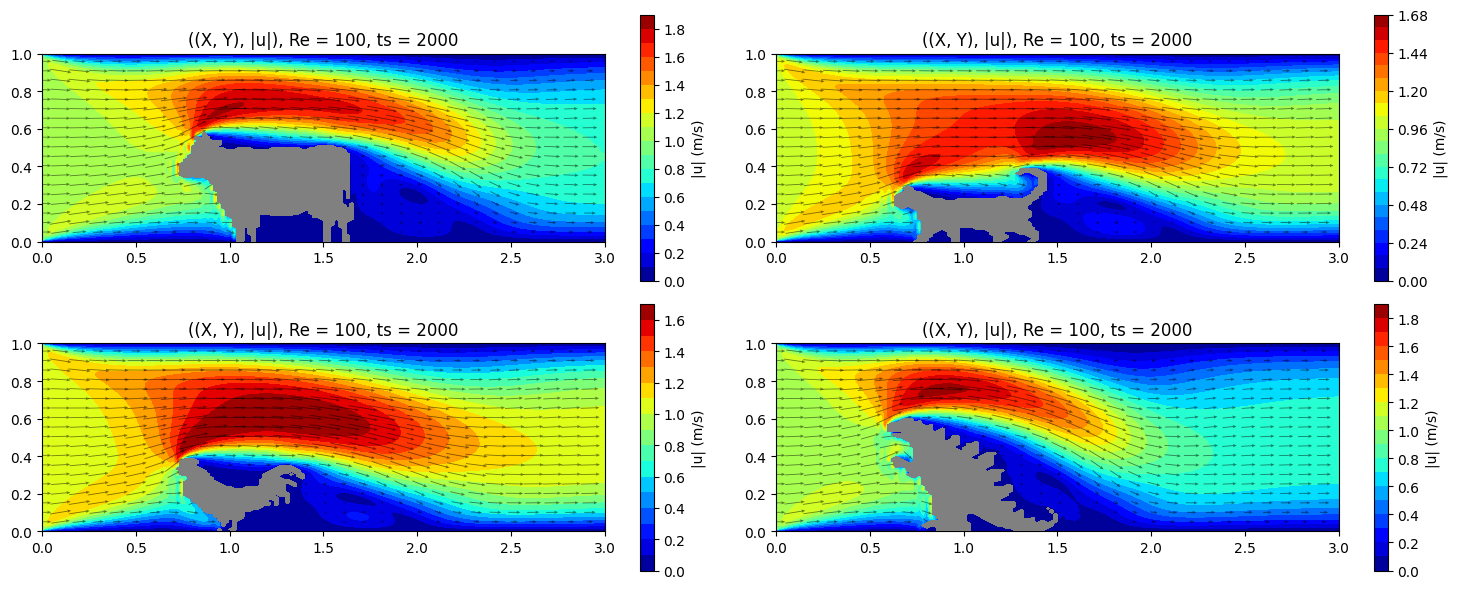

In [5]:
import matplotlib.pyplot as plt
import numpy as np

quiver_step = 5
scale = 30
width = 0.0015
headwidth = 3.8
headlength = 4.5
headaxislength = 4.0

fig, ax = plt.subplots(2, 2, figsize=(15, 6))
ax1 = ax[0, 0]
ax2 = ax[0, 1]
ax3 = ax[1, 0]
ax4 = ax[1, 1]


def plot_zoo(ax, u, v, obstacle):
    
    speed = np.sqrt(u**2 + v**2)
    
    u_sub = u[::quiver_step, ::quiver_step]
    v_sub = v[::quiver_step, ::quiver_step]
    
    cf = ax.contourf(X, Y, speed, levels=20, cmap='jet')
    ax.contourf(X, Y, obstacle, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.quiver(x_sub, y_sub, u_sub, v_sub,
              scale=scale, width=width, alpha=0.5,
              headwidth=headwidth, headlength=headlength, headaxislength=headaxislength,
              color='black', pivot='mid', zorder=2)  
    ax.set_title(f'((X, Y), |u|), Re = {Re}, ts = {nt - 1}')
    ax.set_aspect('equal')
    cbar = fig.colorbar(cf, ax=ax)
    cbar.set_label('|u| (m/s)', fontsize=10)

x_sub = X[::quiver_step, ::quiver_step]
y_sub = Y[::quiver_step, ::quiver_step]

plot_zoo(ax1, u_final_cow, v_final_cow, obstacle_cow)
plot_zoo(ax2, u_final_cat, v_final_cat, obstacle_cat)
plot_zoo(ax3, u_final_cick, v_final_cick, obstacle_cick)
plot_zoo(ax4, u_final_gozila, v_final_gozila, obstacle_gozila)

plt.tight_layout()
plt.show()

In [ ]:
def Cd(u, obstacle, rho, U, dy):
    
    solid_rows, solid_cols = np.where(obstacle)
    
    if len(solid_rows) == 0:
        return 0.0
    
    frontal_height = (np.max(solid_rows) - np.min(solid_rows) + 1) * dy
    A = frontal_height * 1.0

    u_out = u[:, -1]
    Fd = np.sum(rho * u_out * (U - u_out)) * dy
    
    Cd = Fd / (0.5 * rho * U**2 * A)
    return Cd

def Fd(u, obstacle, rho, U, dy):
    
    solid_rows, solid_cols = np.where(obstacle)
    
    if len(solid_rows) == 0:
        return 0.0
    
    frontal_height = (np.max(solid_rows) - np.min(solid_rows) + 1) * dy
    A = frontal_height * 1.0

    u_out = u[:, -1]
    Fd = np.sum(rho * u_out * (U - u_out)) * dy
    
    return Fd



In [69]:
r1 = 1.0
cd_cow = Cd(u_final_cow, obstacle_cow, rho=r1, U=1, dy=dy)
cd_cat = Cd(u_final_cat, obstacle_cat, rho=r1, U=1, dy=dy)
cd_cick = Cd(u_final_cick, obstacle_cick, rho=r1, U=1, dy=dy)
cd_godzila = Cd(u_final_gozila, obstacle_gozila, rho=r1, U=1, dy=dy)

r1 = 1.0
fd_cow_1 = Fd(u_final_cow, obstacle_cow, rho=r1, U=1, dy=dy)
fd_cat_1 = Fd(u_final_cat, obstacle_cat, rho=r1, U=1, dy=dy)
fd_cick_1 = Fd(u_final_cick, obstacle_cick, rho=r1, U=1, dy=dy)
fd_godzila_1 = Fd(u_final_gozila, obstacle_gozila, rho=r1, U=1, dy=dy)

r2 = 10.0
fd_cow_2 = Fd(u_final_cow, obstacle_cow, rho=r2, U=1, dy=dy)
fd_cat_2 = Fd(u_final_cat, obstacle_cat, rho=r2, U=1, dy=dy)
fd_cick_2 = Fd(u_final_cick, obstacle_cick, rho=r2, U=1, dy=dy)
fd_godzila_2 = Fd(u_final_gozila, obstacle_gozila, rho=r2, U=1, dy=dy)

r3 = 20.0
fd_cow_3 = Fd(u_final_cow, obstacle_cow, rho=r3, U=1, dy=dy)
fd_cat_3 = Fd(u_final_cat, obstacle_cat, rho=r3, U=1, dy=dy)
fd_cick_3 = Fd(u_final_cick, obstacle_cick, rho=r3, U=1, dy=dy)
fd_godzila_3 = Fd(u_final_gozila, obstacle_gozila, rho=r3, U=1, dy=dy)

r4 = 30.0
fd_cow_4 = Fd(u_final_cow, obstacle_cow, rho=r4, U=1, dy=dy)
fd_cat_4 = Fd(u_final_cat, obstacle_cat, rho=r4, U=1, dy=dy)
fd_cick_4 = Fd(u_final_cick, obstacle_cick, rho=r4, U=1, dy=dy)
fd_godzila_4 = Fd(u_final_gozila, obstacle_gozila, rho=r4, U=1, dy=dy)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18488\268999366.py:85: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


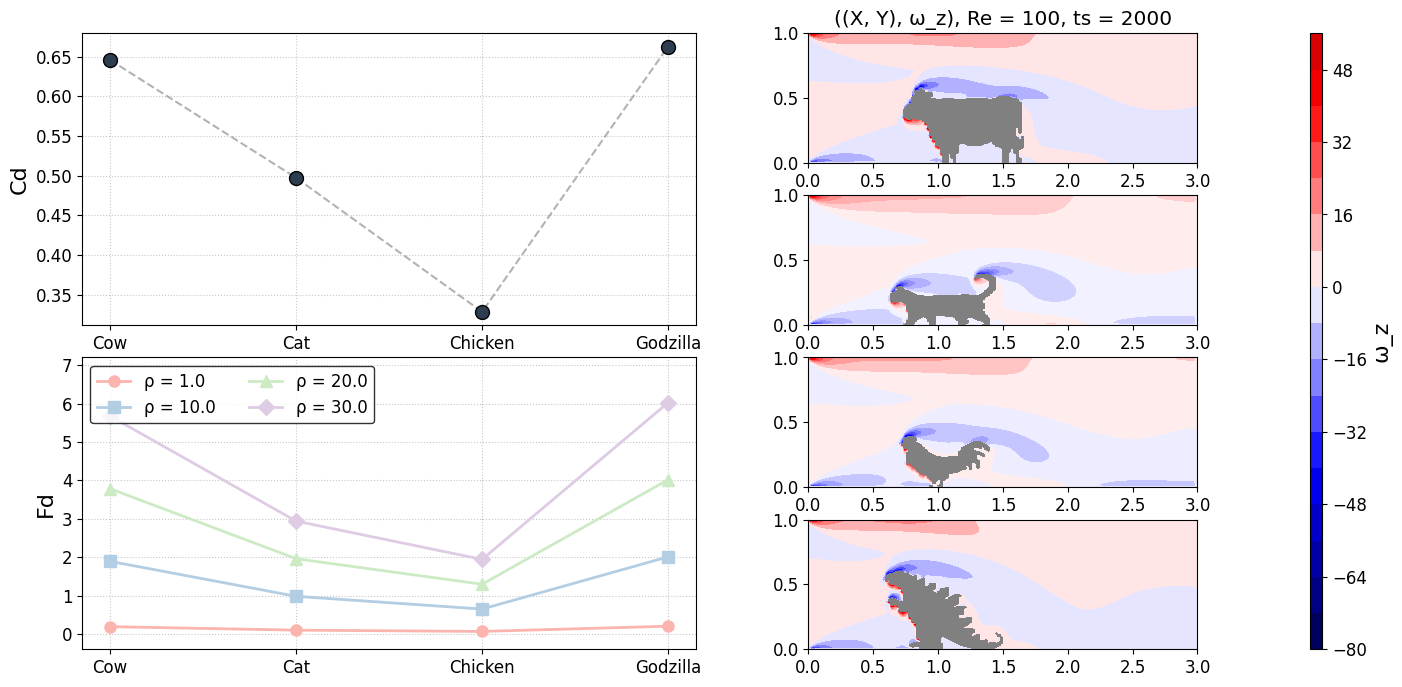

In [75]:
import matplotlib.pyplot as plt
import numpy as np

labels = ['Cow', 'Cat', 'Chicken', 'Godzilla']
x_pos = np.arange(len(labels))

cd = [cd_cow, cd_cat, cd_cick, cd_godzila]
fd_1 = [fd_cow_1, fd_cat_1, fd_cick_1, fd_godzila_1]  
fd_2 = [fd_cow_2, fd_cat_2, fd_cick_2, fd_godzila_2] 
fd_3 = [fd_cow_3, fd_cat_3, fd_cick_3, fd_godzila_3] 
fd_4 = [fd_cow_4, fd_cat_4, fd_cick_4, fd_godzila_4]

plt.rcParams.update({'font.size': 12, 'font.family': 'sans-serif'})

fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(4, 3, width_ratios=[1, 1, 0.02], wspace=0, hspace=0.25)

ax1 = fig.add_subplot(gs[:2, 0])
ax2 = fig.add_subplot(gs[2:, 0])
ax3 = fig.add_subplot(gs[0, 1])
ax4 = fig.add_subplot(gs[1, 1])
ax5 = fig.add_subplot(gs[2, 1])
ax6 = fig.add_subplot(gs[3, 1])
ax7 = fig.add_subplot(gs[:, 2])


ax1.scatter(x_pos, cd, color='#2c3e50', s=100, edgecolor='black', zorder=3)
ax1.plot(x_pos, cd, color='gray', linestyle='--', alpha=0.6, zorder=2)

ax1.set_xticks(x_pos)
ax1.set_xticklabels(labels)
ax1.set_ylabel('Cd', fontsize=16)
ax1.grid(True, linestyle=':', alpha=0.7)

colors = ['#fbb4ae', '#b3cde3', '#ccebc5', '#decbe4']
markers = ['o', 's', '^', 'D']

ax2.plot(x_pos, fd_1, label=f'ρ = {r1}', c=colors[0], linewidth=2, marker=markers[0], markersize=8)
ax2.plot(x_pos, fd_2, label=f'ρ = {r2}', c=colors[1], linewidth=2, marker=markers[1], markersize=8)
ax2.plot(x_pos, fd_3, label=f'ρ = {r3}', c=colors[2], linewidth=2, marker=markers[2], markersize=8)
ax2.plot(x_pos, fd_4, label=f'ρ = {r4}', c=colors[3], linewidth=2, marker=markers[3], markersize=8)

ax2.set_xticks(x_pos)
ax2.set_xticklabels(labels)
ax2.set_ylabel('Fd', fontsize=16)
ax2.set_ylim(-0.4, 7.2)
ax2.grid(True, linestyle=':', alpha=0.7)

legend = ax2.legend(loc="upper left", ncol = 2) #frameon=True, shadow=True, 
legend.get_frame().set_edgecolor('black')


def plot_zoo(ax, vortice, obstacle, t):
    cf = ax.contourf(X, Y, vortice, levels=20, cmap='RdBu_r')
    ax.contourf(X, Y, obstacle, levels=[0.5, 1.5], colors='gray', zorder=3)
    if t == 0:
        ax.set_title(f'((X, Y), |u|), Re = {Re}, ts = {nt - 1}')
    else:
        None
    ax.set_aspect('equal')

vmin, vmax = -80, 80
cmapp = 'seismic'

cf1 = ax3.contourf(X, Y, vortice_cow, levels=20, vmin=vmin, vmax=vmax, cmap=cmapp)
ax3.contourf(X, Y, obstacle_cow, levels=[0.5, 1.5], colors='gray', zorder=3)
ax3.set_title(f'((X, Y), ω_z), Re = {Re}, ts = {nt - 1}')
ax3.set_aspect('equal')

cf2 = ax4.contourf(X, Y, vortice_cat, levels=20, vmin=vmin, vmax=vmax, cmap=cmapp)
ax4.contourf(X, Y, obstacle_cat, levels=[0.5, 1.5], colors='gray', zorder=3)
ax4.set_aspect('equal')

cf3 = ax5.contourf(X, Y, vortice_cick, levels=20, vmin=vmin, vmax=vmax, cmap=cmapp)
ax5.contourf(X, Y, obstacle_cick, levels=[0.5, 1.5], colors='gray', zorder=3)
ax5.set_aspect('equal')

cf4 = ax6.contourf(X, Y, vortice_gozila, levels=20, vmin=vmin, vmax=vmax, cmap=cmapp)
ax6.contourf(X, Y, obstacle_gozila, levels=[0.5, 1.5], colors='gray', zorder=3)
ax6.set_aspect('equal')

cbar = fig.colorbar(cf4, cax=ax7) 
cbar.set_label('ω_z', fontsize=16)

plt.tight_layout()
plt.show()